# Cell-cell communication

Which ligands secreted by THP1 cells are likely to signal to K562 cells after LPS stimulation?

`cp.tl.c2c.infer` takes the secreted ligand-receptor pairs from CellChatDB, keeps those whose ligand genes are detected in THP1 cells and whose receptor genes are detected in K562 cells, and scores each pair by:

- its **early LR activity**: ligand expression × receptor availability relative to time 0, summed over the time points in `causal_window` (0–45 min), and
- the **ligand's temporal association** in THP1 cells (tradeSeq, -log10 p).


In [1]:
import os
from pathlib import Path

import pandas as pd
import scanpy as sc

import chronopack as cp

# Folder holding one sub-folder per experiment; see analyses/README.md.
DATA_DIR = Path(os.environ.get("CHRONOPACK_DATA_DIR", "../data"))
EXP_DIR = DATA_DIR / "thp1-k562-lps.hg38.rep"
OUTPUT_DIR = DATA_DIR / "c2c"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

adata = sc.read_h5ad(EXP_DIR / "output/adata_full.chk1.h5ad")
adata

AnnData object with n_obs × n_vars = 3915 × 21693
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_genes', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden_unintegrated', 'THP1_score', 'K562_score', 'THP1_minus_K562', 'cell_type', 'traj_clusters', 'terminal_fate_probs_traj_0', 'terminal_fate_probs_traj_1', 'terminal_fate_probs_traj_2', 'fate_0', 'fate_1', 'fate_2', 'fate_entropy', 'fate_maxprob', 'traj_clusters_mass_ret_cell'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'cell_type_colors', 'chronopack', 'hvg', 'leiden_unintegrated', 'leiden_unintegrated_colors', 'log1p', 'neighbors', 'ot_graph', 'ot_umap', 'pca', 'phase_colors', 'sample_colors', 'scrublet', 'terminal_cell_dist_idx_last', 'terminal_fate_probs_tra

## Infer ligand-receptor communication

In [2]:
c2c = cp.tl.c2c.infer(
    adata=adata,
    lr_resource="../resources/interaction_input_CellChatDB.csv",
    association=EXP_DIR / "intmd/sc-THP1_to_tradeSeq.fixed/asso_df.1trajectory.nknots4.csv",
    sender="THP1",
    receiver="K562",
    causal_window=(0, 45),
)
c2c.ligand_scores.head(20)

,ligand,ligand_significance,max_lr_activity,best_pair,best_pair_rank,n_receptor_pairs,current_ligand_rank,z_ligand_significance,z_max_lr_activity,composite_score,zscore_composite_rank
0,TNF,3.000000,0.590795,TNF->TNFRSF1B,1,2,1,1.579854,6.297032,7.876886,1
1,CXCL3,3.000000,0.057186,CXCL3->ACKR1,3,1,2,1.579854,0.484928,2.064782,2
2,CCL3,3.000000,0.042501,CCL3->CCR1,4,3,3,1.579854,0.324979,1.904833,3
3,CCL4,3.000000,0.038899,CCL4->ACKR2,5,2,4,1.579854,0.285739,1.865593,4
4,CXCL2,3.000000,0.035995,CXCL2->ACKR1,6,1,5,1.579854,0.254110,1.833964,5
5,CXCL1,3.000000,0.035023,CXCL1->ACKR1,7,1,6,1.579854,0.243528,1.823381,6
6,CXCL8,3.000000,0.021986,CXCL8->ACKR1,9,1,7,1.579854,0.101527,1.681381,7
7,CCL5,3.000000,0.003494,CCL5->CCR1,12,5,8,1.579854,-0.099889,1.479965,8
8,CCL3L3,3.000000,-0.000076,CCL3L3->CCR1,17,1,9,1.579854,-0.138777,1.441077,9
9,IL1B,3.000000,-0.009710,IL1B->IL1R1_IL1RAP,18,1,10,1.579854,-0.243706,1.336148,10


In [3]:
c2c.write(OUTPUT_DIR / "chronopack_c2c")

{'interactions_csv': '/new-stg/home/alex/tmp/ChronoPack/verification_runs/full_pipeline_analyses_20260930_r9/data/c2c/chronopack_c2c/chronopack_c2c.interactions.csv', 'ligand_scores_csv': '/new-stg/home/alex/tmp/ChronoPack/verification_runs/full_pipeline_analyses_20260930_r9/data/c2c/chronopack_c2c/chronopack_c2c.ligand_scores.csv', 'metadata': '/new-stg/home/alex/tmp/ChronoPack/verification_runs/full_pipeline_analyses_20260930_r9/data/c2c/chronopack_c2c/chronopack_c2c.metadata.json', 'temporal_profiles_csv': '/new-stg/home/alex/tmp/ChronoPack/verification_runs/full_pipeline_analyses_20260930_r9/data/c2c/chronopack_c2c/chronopack_c2c.temporal_profiles.csv', 'candidate_interactions_csv': '/new-stg/home/alex/tmp/ChronoPack/verification_runs/full_pipeline_analyses_20260930_r9/data/c2c/chronopack_c2c/chronopack_c2c.candidate_interactions.csv'}

## Plots

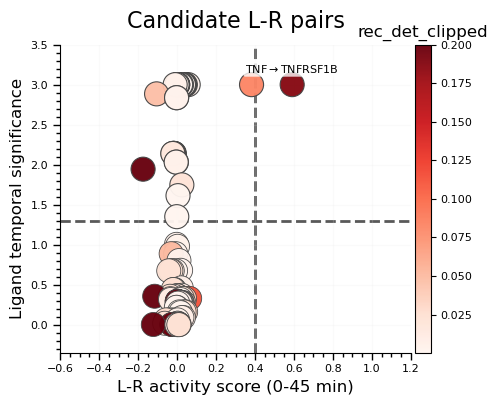

In [4]:
fig, ax = cp.pl.c2c.interaction_scatter(c2c, x_thresh=0.4, xlim=(-0.6, 1.2))
fig.savefig(OUTPUT_DIR / "chronopack_lr_pair_scores.png", dpi=300, bbox_inches="tight")

TNF → TNFRSF1A activity against the K562 NFKBIA response, using fitted curves from the THP1 and K562 tradeSeq screen fits.

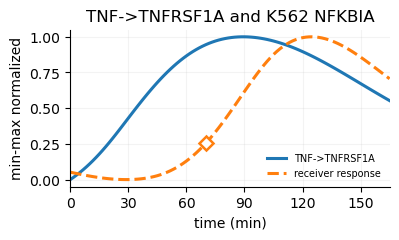

In [5]:
thp1, k562 = cp.tl.c2c.split_by_cell_type(adata, sender="THP1", receiver="K562")

# Fitted curves for the sender (THP1, lineage "L2") and receiver (K562, lineage "L1") genes.
fits = pd.concat([
    cp.tl.predict_gene_dynamics(EXP_DIR / "intmd/sc-THP1_to_tradeSeq.fixed", ["TNF"]).assign(lineage="L2"),
    cp.tl.predict_gene_dynamics(EXP_DIR / "intmd/sc-K562_to_tradeSeq.fixed", ["TNFRSF1A", "NFKBIA"]).assign(lineage="L1"),
])

tnf = cp.tl.c2c.build_pair_series(
    pd.DataFrame({"ligand": ["TNF"], "receptor": ["TNFRSF1A"]}),
    sender_adata=thp1,
    receiver_adata=k562,
    response_genes=["NFKBIA"],
    prefer_fits=True,
    fits_df=fits,
)
fig, ax = cp.pl.c2c.plot_pair_overlay(
    tnf,
    pair=("TNF", "TNFRSF1A"),
    norm_mode="minmax",
    nfkb_onset_time=70,
    figsize=(4, 2.5),
    title="TNF->TNFRSF1A and K562 NFKBIA",
)
fig.savefig(OUTPUT_DIR / "TNF_TNFRSF1A_NFKBIA_overlay.png", dpi=300, bbox_inches="tight")

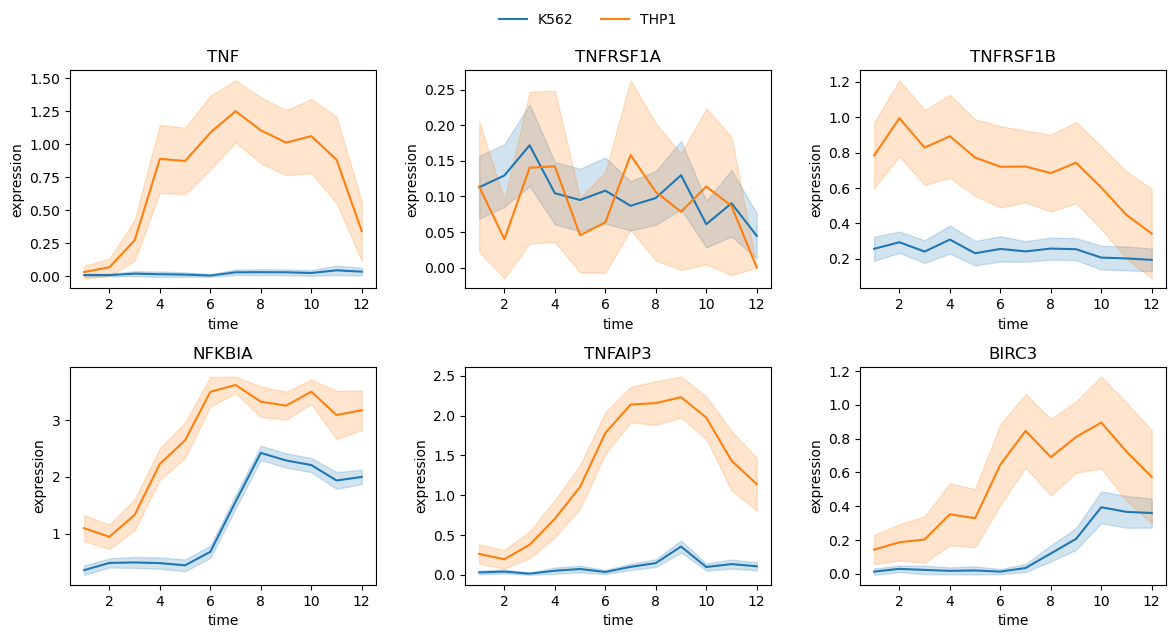

In [6]:
fig, axes = cp.pl.c2c.plot_genes_over_time(
    adata,
    ["TNF", "TNFRSF1A", "TNFRSF1B", "NFKBIA", "TNFAIP3", "BIRC3"],
    layer="log1p",
)
fig.savefig(OUTPUT_DIR / "selected_gene_expression_over_time.png", dpi=300, bbox_inches="tight")